In [1]:
   %pip install statsbombpy pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
   %pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install scikit-learn matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np, pandas as pd
from statsbombpy import sb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss, brier_score_loss

matches = sb.matches(competition_id=43, season_id=3)

frames = []
for mid in matches.match_id:
    ev = sb.events(match_id=mid)
    frames.append(ev[ev.type == "Shot"])
shots = pd.concat(frames)

# Drop penalties, they're a different problem
shots = shots[shots.shot_type != "Penalty"].copy()

# Features (StatsBomb pitch is 120x80, goal centered at y=40, width 8)
shots["x"] = shots.location.str[0]
shots["y"] = shots.location.str[1]
dx, dy = 120 - shots.x, 40 - shots.y
shots["dist"] = np.sqrt(dx**2 + dy**2)
shots["angle"] = np.arctan2(8 * dx, dx**2 + dy**2 - 16)
shots["header"] = (shots.shot_body_part == "Head").astype(int)
shots["goal"] = (shots.shot_outcome == "Goal").astype(int)

X = shots[["dist", "angle", "header"]]
y = shots.goal
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)

model = LogisticRegression().fit(X_tr, y_tr)
p = model.predict_proba(X_te)[:, 1]
print("log loss:", log_loss(y_te, p), "Brier:", brier_score_loss(y_te, p))

/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data acc

log loss: 0.249143544189053 Brier: 0.06947840703730196


In [5]:
import os
os.makedirs("data", exist_ok=True)
shots.to_pickle("data/wc2018_shots.pkl")

In [6]:
shots = pd.read_pickle("data/wc2018_shots.pkl")

In [7]:
base_rate = y_tr.mean()
baseline = np.full(len(y_te), base_rate)
print("goal rate:", round(base_rate, 3))
print("baseline log loss:", log_loss(y_te, baseline))
print("model log loss:   ", log_loss(y_te, p))

goal rate: 0.082
baseline log loss: 0.2858631944349934
model log loss:    0.249143544189053


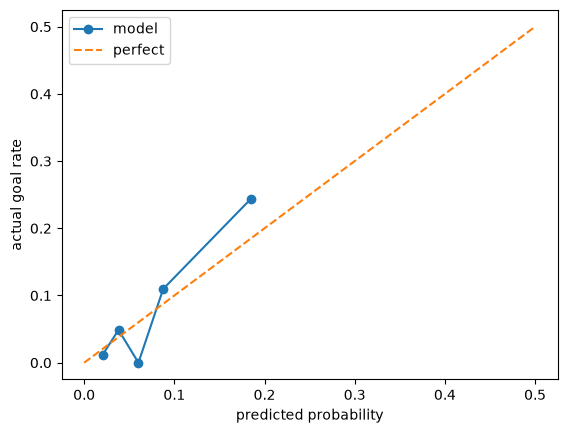

In [8]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

frac_goals, mean_pred = calibration_curve(y_te, p, n_bins=5, strategy="quantile")
plt.plot(mean_pred, frac_goals, "o-", label="model")
plt.plot([0, 0.5], [0, 0.5], "--", label="perfect")
plt.xlabel("predicted probability")
plt.ylabel("actual goal rate")
plt.legend()
plt.show()

In [9]:
test_shots = pd.DataFrame({
    "dist":   [6, 12, 25],
    "angle":  [0.9, 0.5, 0.2],
    "header": [0, 0, 0],
})
print(model.predict_proba(test_shots)[:, 1])

[0.28109301 0.12927769 0.03363559]


In [10]:
comps = sb.competitions()
comps[["competition_id","season_id","competition_name","season_name"]].drop_duplicates()

/opt/anaconda3/envs/soccer/lib/python3.13/site-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


,competition_id,season_id,competition_name,season_name
0,9,281,1. Bundesliga,2023/2024
1,9,27,1. Bundesliga,2015/2016
2,1267,107,African Cup of Nations,2023
3,16,4,Champions League,2018/2019
4,16,1,Champions League,2017/2018
...,...,...,...,...
75,35,75,UEFA Europa League,1988/1989
76,53,315,UEFA Women's Euro,2025
77,53,106,UEFA Women's Euro,2022
78,72,107,Women's World Cup,2023


In [11]:
pd.set_option("display.max_rows", 200)
comps[["competition_id","season_id","competition_name","season_name"]].drop_duplicates().sort_values(["competition_name","season_name"])

,competition_id,season_id,competition_name,season_name
1,9,27,1. Bundesliga,2015/2016
0,9,281,1. Bundesliga,2023/2024
2,1267,107,African Cup of Nations,2023
20,16,276,Champions League,1970/1971
19,16,71,Champions League,1971/1972
18,16,277,Champions League,1972/1973
17,16,76,Champions League,1999/2000
16,16,44,Champions League,2003/2004
15,16,37,Champions League,2004/2005
14,16,39,Champions League,2006/2007


In [4]:
import os, warnings
warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)

to_pull = [(43, 3), (9, 27), (9, 281)]   # (competition_id, season_id)

def pull_shots(comp_id, season_id):
    path = f"data/shots_{comp_id}_{season_id}.pkl"
    if os.path.exists(path):
        return pd.read_pickle(path)
    matches = sb.matches(competition_id=comp_id, season_id=season_id)
    print(f"{comp_id}/{season_id}: {len(matches)} matches")
    frames = []
    for _, m in matches.iterrows():
        try:
            ev = sb.events(match_id=m.match_id)
        except Exception as e:
            print("skipped", m.match_id, e)
            continue
        s = ev[ev.type == "Shot"].copy()
        s["competition_id"] = comp_id
        s["season_id"] = season_id
        s["match_date"] = m.match_date
        frames.append(s)
    out = pd.concat(frames)
    out.to_pickle(path)
    return out

all_shots = pd.concat([pull_shots(c, s) for c, s in to_pull])
print(len(all_shots), "shots")

3462 shots


In [13]:
shots = all_shots[all_shots.shot_type != "Penalty"].copy()
shots["x"] = shots.location.str[0]
shots["y"] = shots.location.str[1]
dx, dy = 120 - shots.x, 40 - shots.y
shots["dist"] = np.sqrt(dx**2 + dy**2)
shots["angle"] = np.arctan2(8 * dx, dx**2 + dy**2 - 16)
shots["header"] = (shots.shot_body_part == "Head").astype(int)
shots["goal"] = (shots.shot_outcome == "Goal").astype(int)

feats = ["dist", "angle", "header"]
train = shots[shots.match_date < "2020-01-01"]   # 2015/16 + 2018 World Cup
test  = shots[shots.match_date >= "2020-01-01"]  # 2023/24

model = LogisticRegression().fit(train[feats], train.goal)
p = model.predict_proba(test[feats])[:, 1]
base = np.full(len(test), train.goal.mean())

print(len(train), "train shots,", len(test), "test shots")
print("baseline log loss:", log_loss(test.goal, base))
print("model log loss:   ", log_loss(test.goal, p))

2468 train shots, 908 test shots
baseline log loss: 0.3548107618623345
model log loss:    0.31100398794817863


In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def in_triangle(px, py, a, b, c):
    def s(p1, p2, p3):
        return (p1[0]-p3[0])*(p2[1]-p3[1]) - (p2[0]-p3[0])*(p1[1]-p3[1])
    p = (px, py)
    d1, d2, d3 = s(p, a, b), s(p, b, c), s(p, c, a)
    neg = d1 < 0 or d2 < 0 or d3 < 0
    pos = d1 > 0 or d2 > 0 or d3 > 0
    return not (neg and pos)

def freeze_feats(row):
    ff = row.shot_freeze_frame
    if not isinstance(ff, list):
        return pd.Series({"n_def_cone": np.nan, "gk_dist": np.nan})
    a, b, c = (row.x, row.y), (120, 36), (120, 44)
    n_def, gk_dist = 0, np.nan
    for p in ff:
        px, py = p["location"]
        if p["position"]["name"] == "Goalkeeper" and not p["teammate"]:
            gk_dist = np.hypot(px - row.x, py - row.y)
        elif not p["teammate"] and in_triangle(px, py, a, b, c):
            n_def += 1
    return pd.Series({"n_def_cone": n_def, "gk_dist": gk_dist})

shots[["n_def_cone", "gk_dist"]] = shots.apply(freeze_feats, axis=1)

for c in ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]:
    shots[c] = shots[c].fillna(False).astype(int) if c in shots else 0

shots["n_def_cone"] = shots.n_def_cone.fillna(shots.n_def_cone.median())
shots["gk_dist"] = shots.gk_dist.fillna(shots.gk_dist.median())

feats2 = ["dist", "angle", "header", "n_def_cone", "gk_dist",
          "under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]

train = shots[shots.match_date < "2020-01-01"]
test  = shots[shots.match_date >= "2020-01-01"]

model2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model2.fit(train[feats2], train.goal)
p2 = model2.predict_proba(test[feats2])[:, 1]

print("v1 log loss:", log_loss(test.goal, p))
print("v2 log loss:", log_loss(test.goal, p2))

v1 log loss: 0.31100398794817863
v2 log loss: 0.30679651815652187


In [15]:
   rows = []
   for _, r in comps.drop_duplicates(["competition_id","season_id"]).iterrows():
       n = len(sb.matches(competition_id=r.competition_id, season_id=r.season_id))
       rows.append((r.competition_name, r.season_name, r.competition_id, r.season_id, n))
   pd.DataFrame(rows, columns=["comp","season","cid","sid","matches"]).sort_values("matches", ascending=False).head(25)

,comp,season,cid,sid,matches
70,Serie A,2015/2016,12,27,380
45,La Liga,2015/2016,11,27,380
68,Premier League,2015/2016,2,27,380
63,Ligue 1,2015/2016,7,27,377
58,Liga F,2023/2024,182,281,240
66,NWSL,2023,49,107,137
38,Frauen Bundesliga,2023/2024,135,281,132
25,FA Women's Super League,2023/2024,37,281,132
26,FA Women's Super League,2020/2021,37,90,131
72,Serie A Women,2023/2024,131,281,130


In [16]:
to_pull = [(2, 27), (11, 27)]    # Premier League, La Liga 2015/16
new_shots = pd.concat([pull_shots(c, s) for c, s in to_pull])
print(len(new_shots), "shots")

2/27: 380 matches
11/27: 380 matches
19076 shots


In [18]:
to_pull = [(12, 27), (7, 27)]    # Premier League, La Liga 2015/16
new_shots = pd.concat([pull_shots(c, s) for c, s in to_pull])
print(len(new_shots), "shots")

7/27: 377 matches
18812 shots


In [1]:
def build_features(df):
    df = df[df.shot_type != "Penalty"].copy()
    df["x"] = df.location.str[0]
    df["y"] = df.location.str[1]
    # ... your dist, angle, header, goal lines
    # ... your freeze_feats apply, fillna lines
    return df

In [2]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss

def in_triangle(px, py, a, b, c):
    def s(p1, p2, p3):
        return (p1[0]-p3[0])*(p2[1]-p3[1]) - (p2[0]-p3[0])*(p1[1]-p3[1])
    p = (px, py)
    d1, d2, d3 = s(p, a, b), s(p, b, c), s(p, c, a)
    neg = d1 < 0 or d2 < 0 or d3 < 0
    pos = d1 > 0 or d2 > 0 or d3 > 0
    return not (neg and pos)

def freeze_feats(row):
    ff = row.shot_freeze_frame
    if not isinstance(ff, list):
        return pd.Series({"n_def_cone": np.nan, "gk_dist": np.nan})
    a, b, c = (row.x, row.y), (120, 36), (120, 44)
    n_def, gk_dist = 0, np.nan
    for p in ff:
        px, py = p["location"]
        if p["position"]["name"] == "Goalkeeper" and not p["teammate"]:
            gk_dist = np.hypot(px - row.x, py - row.y)
        elif not p["teammate"] and in_triangle(px, py, a, b, c):
            n_def += 1
    return pd.Series({"n_def_cone": n_def, "gk_dist": gk_dist})

feats  = ["dist", "angle", "header"]
feats2 = ["dist", "angle", "header", "n_def_cone", "gk_dist",
          "under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]

def build_features(df):
    df = df[df.shot_type != "Penalty"].copy()
    df["x"] = df.location.str[0]
    df["y"] = df.location.str[1]
    dx, dy = 120 - df.x, 40 - df.y
    df["dist"] = np.sqrt(dx**2 + dy**2)
    df["angle"] = np.arctan2(8 * dx, dx**2 + dy**2 - 16)
    df["header"] = (df.shot_body_part == "Head").astype(int)
    df["goal"] = (df.shot_outcome == "Goal").astype(int)

    df[["n_def_cone", "gk_dist"]] = df.apply(freeze_feats, axis=1)
    df["n_def_cone"] = df.n_def_cone.fillna(df.n_def_cone.median())
    df["gk_dist"] = df.gk_dist.fillna(df.gk_dist.median())

    for c in ["under_pressure", "shot_first_time", "shot_one_on_one", "shot_open_goal"]:
        df[c] = df[c].fillna(False).astype(int) if c in df else 0
    return df

In [5]:
all_shots = pd.concat([pull_shots(c, s) for c, s in
                       [(43,3), (9,27), (9,281), (2,27), (11,27), (12,27), (7,27)]])
shots = build_features(all_shots)

league = shots[shots.competition_id.isin([2, 11, 12, 7])]
train = league[league.match_date < "2016-03-01"]
test  = league[league.match_date >= "2016-03-01"]
print(len(train), "train shots,", len(test), "test shots")

base = np.full(len(test), train.goal.mean())
m1 = LogisticRegression().fit(train[feats], train.goal)
m2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[feats2], train.goal)

print("baseline:", log_loss(test.goal, base))
print("v1:      ", log_loss(test.goal, m1.predict_proba(test[feats])[:, 1]))
print("v2:      ", log_loss(test.goal, m2.predict_proba(test[feats2])[:, 1]))

26570 train shots, 10918 test shots
baseline: 0.3262367417198926
v1:       0.2785661088528207
v2:       0.2711645003865641


In [22]:
%pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 1.2 MB/s  0:00:01m 1.2 MB/s eta 0:00:010m
Note: you may need to restart the kernel to use updated packages.


In [6]:
from lightgbm import LGBMClassifier

gbm = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=8,
                     min_child_samples=50, subsample=0.8, subsample_freq=1,
                     colsample_bytree=0.8, verbose=-1)
gbm.fit(train[feats2], train.goal)
p_gbm = gbm.predict_proba(test[feats2])[:, 1]
print("v2 logistic:", log_loss(test.goal, m2.predict_proba(test[feats2])[:, 1]))
print("LightGBM:   ", log_loss(test.goal, p_gbm))

v2 logistic: 0.2711645003865641
LightGBM:    0.2648962185188338


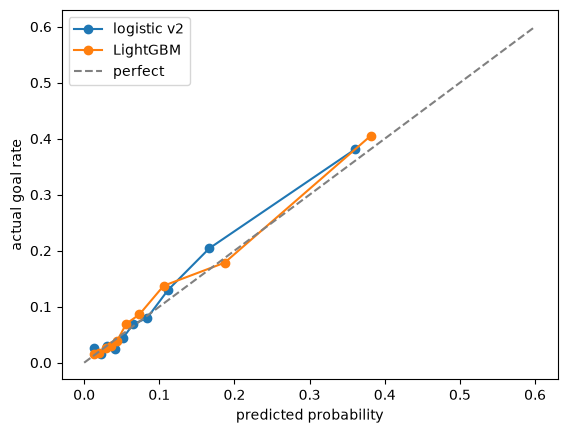

In [7]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

p_v2 = m2.predict_proba(test[feats2])[:, 1]
for name, pp in [("logistic v2", p_v2), ("LightGBM", p_gbm)]:
    frac, mean_pred = calibration_curve(test.goal, pp, n_bins=10, strategy="quantile")
    plt.plot(mean_pred, frac, "o-", label=name)
plt.plot([0, 0.6], [0, 0.6], "--", color="gray", label="perfect")
plt.xlabel("predicted probability"); plt.ylabel("actual goal rate")
plt.legend(); plt.show()

In [8]:
stress = shots[shots.competition_id.isin([43, 9])]
base_s = np.full(len(stress), train.goal.mean())
print(len(stress), "stress shots")
print("baseline:", log_loss(stress.goal, base_s))
print("v2:      ", log_loss(stress.goal, m2.predict_proba(stress[feats2])[:, 1]))
print("LightGBM:", log_loss(stress.goal, gbm.predict_proba(stress[feats2])[:, 1]))

3376 stress shots
baseline: 0.3128177604719336
v2:       0.2696524167767426
LightGBM: 0.26190561739097795
